# Hito 2 — Sistema RAG

Sistema de verificación de hechos sobre mitología griega, romana y nórdica.

En el Hito 1 se construyó el corpus (5.035 documentos partidos en 19.792 fragmentos), un conjunto de 84 queries de evaluación y el baseline de recuperación dispersa: **BM25**, con Recall@10 = 0,845 y MRR = 0,645. En este hito se construye el sistema RAG completo:

1. **Recuperación densa**: los mismos fragmentos, representados con *sentence embeddings* y guardados en una base de datos vectorial, evaluados con las mismas queries y comparados con BM25.
2. **Generación**: un LLM de pesos abiertos que, con los fragmentos recuperados, da un veredicto sobre la afirmación, cita sus fuentes, no responde si no hay pruebas y contesta en el idioma de la pregunta.
3. **Evaluación de la generación**: calidad de los veredictos, cobertura y tiempo de respuesta.

La base vectorial se crea con `src/indexa_vectores.py`; aquí solo se carga.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mismo estilo de gráficas que en el Hito 1, con un color fijo por método
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8984',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False,
})
COLOR = {'BM25': '#2a78d6', 'e5': '#1baf7a', 'bge': '#eda100'}
GRIS = '#8a8984'

RAIZ = Path('..')
DATOS = RAIZ / 'data'
sys.path.append(str(RAIZ / 'src'))

def leer_jsonl(ruta):
    with open(ruta, encoding='utf-8') as f:
        return [json.loads(linea) for linea in f]

chunks = pd.DataFrame(leer_jsonl(DATOS / 'processed' / 'chunks.jsonl'))
chunks = chunks[['chunk_id', 'doc_id', 'fuente', 'titulo', 'seccion', 'n_palabras', 'texto']]
tokens = leer_jsonl(DATOS / 'processed' / 'chunks_tokens.jsonl')
assert [t['chunk_id'] for t in tokens] == chunks['chunk_id'].tolist()
corpus = [t['tokens'] for t in tokens]

queries = leer_jsonl(DATOS / 'queries.jsonl')
relevant = [set(q['relevant_ids']) for q in queries]
assert all(r <= set(chunks['doc_id']) for r in relevant), 'Hay queries cuyo documento no está en el corpus'

titulo_de_doc = chunks.drop_duplicates('doc_id').set_index('doc_id')['titulo']
doc_de_fila = chunks['doc_id'].values
fila_de_chunk = {cid: i for i, cid in enumerate(chunks['chunk_id'])}

print(f"{chunks['doc_id'].nunique()} documentos, {len(chunks)} fragmentos, {len(queries)} queries")

5035 documentos, 19792 fragmentos, 84 queries


Las funciones de evaluación son las del Hito 1, para que los números sean comparables:

- **De fragmentos a documentos**: para pedir $k$ documentos se recuperan $20k$ fragmentos (como mínimo 200) y cada documento puntúa con su mejor fragmento.
- **Métricas**: Recall@5, @10, @50 y @100 y MRR@10.
- **Intervalos de confianza del 95 %** por *bootstrap* (2.000 remuestreos de las queries) y **diferencias emparejadas** entre sistemas: una diferencia es clara si su intervalo no incluye el 0.

In [2]:
K, K_MAX = 10, 100
CORTES = (5, 10, 50, 100)
B_BOOTSTRAP = 2000

def n_fragmentos(k):
    return max(200, 20 * k)

def a_documentos(filas, k):
    # Los fragmentos vienen ordenados de mejor a peor: cada documento se queda con su primera aparición
    docs, vistos = [], set()
    for fila in filas:
        d = doc_de_fila[fila]
        if d not in vistos:
            vistos.add(d)
            docs.append(d)
            if len(docs) == k:
                break
    return docs

def posicion(ranking, rel):
    return next((i for i, d in enumerate(ranking, 1) if d in rel), None)

def aciertos(rankings, relevant, cortes=CORTES, k_mrr=K):
    # Una fila por query: Recall@K de cada corte y el recíproco de la posición (para el MRR)
    filas = []
    for r, rel in zip(rankings, relevant):
        fila = {f'Recall@{c}': len(set(r[:c]) & rel) / len(rel) for c in cortes}
        p = posicion(r[:k_mrr], rel)
        fila['MRR'] = 1 / p if p else 0.0
        filas.append(fila)
    return pd.DataFrame(filas)

def intervalo(valores, B=B_BOOTSTRAP, semilla=0):
    # Media e intervalo bootstrap del 95 %. Con la misma semilla se remuestrean las mismas queries:
    # aplicado a la diferencia query a query entre dos sistemas, es el bootstrap emparejado.
    v = np.asarray(valores, dtype=float)
    indices = np.random.default_rng(semilla).integers(0, len(v), size=(B, len(v)))
    inf, sup = np.percentile(v[indices].mean(axis=1), [2.5, 97.5])
    return v.mean(), inf, sup

def texto_ic(media, inf, sup):
    return f"{media:.3f} [{inf:.3f}, {sup:.3f}]"

def grafica_diferencias(ax, etiquetas, ics, color, desplazamiento=0, nombre=None):
    # Punto en la diferencia media y línea en su intervalo; relleno si el intervalo no incluye el 0
    y = np.arange(len(etiquetas))[::-1] + desplazamiento
    for yi, (media, inf, sup) in zip(y, ics):
        clara = inf > 0 or sup < 0
        ax.plot([inf, sup], [yi, yi], color=color, lw=2, solid_capstyle='round')
        ax.plot(media, yi, 'o', ms=8, color=color if clara else 'white', mec=color, mew=2,
                label=nombre if yi == y[0] else None)
    ax.axvline(0, color=GRIS, lw=1, ls='--')
    ax.set_yticks(np.arange(len(etiquetas))[::-1], etiquetas)
    ax.grid(axis='y', visible=False)

## 1. Recuperación densa

### 1.1. El baseline: BM25 del Hito 1

Se reconstruye BM25 con la configuración final del Hito 1 (`bm25s`, variante Lucene, $k_1 = 1.5$, $b = 0.75$, lemas de spaCy con el título delante, sin N-gramas, sin filtros y sin normalización). Las queries pasan por el mismo preprocesado que los fragmentos. Si todo está igual, deben salir las cifras del Hito 1: Recall@10 = 0,845 y MRR = 0,645.

In [3]:
import bm25s
from preprocesado import preparar

bm25 = bm25s.BM25(k1=1.5, b=0.75)
bm25.index(corpus, show_progress=False)
vocabulario = {w for doc in corpus for w in doc}
q_tokens = [[w for w in t if w in vocabulario] for t in preparar([q['query'] for q in queries])]

def retrieve_bm25(tokens_query, k=K):
    if not tokens_query:
        return []
    filas, _ = bm25.retrieve([tokens_query], k=n_fragmentos(k), show_progress=False)
    return a_documentos(filas[0], k)

rankings, tiempos = {}, {}
inicio = time.perf_counter()
rankings['BM25'] = [retrieve_bm25(t, k=K_MAX) for t in q_tokens]
tiempos['BM25'] = (time.perf_counter() - inicio) / len(queries)

a_bm25 = aciertos(rankings['BM25'], relevant)
print(a_bm25.mean().round(3).to_string())

/home/santihm/Fact-checking_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Recall@5      0.810
Recall@10     0.845
Recall@50     0.952
Recall@100    0.976
MRR           0.645


Salen exactamente las cifras del Hito 1 (Recall@10 = 0,845 y MRR = 0,645): el corpus, las queries y el preprocesado son los mismos, así que la comparación con la recuperación densa es justa.

### 1.2. Embeddings y base de datos vectorial

En la recuperación densa, cada fragmento se representa con un vector (*embedding*) que resume su significado, calculado con un modelo de lenguaje entrenado para que textos parecidos tengan vectores cercanos. La query se representa igual, y se recuperan los fragmentos cuyo vector está más cerca, con la **similitud coseno**. A diferencia de BM25, no hace falta que la query y el fragmento compartan palabras: *"the islands of the blessed"* puede quedar cerca de *"the Fortunate Isles"*.

**Modelos.** Se comparan dos:

| Modelo | Idiomas | Dimensión | Longitud máxima | Por qué |
|---|---|---|---|---|
| `intfloat/multilingual-e5-base` (**e5**) | ~100, entre ellos inglés y español | 768 | 512 *tokens* | Las afirmaciones pueden llegar en español y el corpus está en inglés: con un modelo multilingüe no hace falta traducir |
| `BAAI/bge-small-en-v1.5` (**bge**) | solo inglés | 384 | 512 *tokens* | Para medir si ser multilingüe cuesta algo con queries en inglés |

Los dos se usan como recomiendan sus autores: e5 con los prefijos `query:` y `passage:`, y bge con una instrucción delante de la query. Como en BM25, a cada fragmento se le pone delante el título de su documento. Con 512 *tokens* caben casi todos los fragmentos enteros: se cortan el 5,7 % con e5 y el 2,9 % con bge (el tokenizador multilingüe parte más las palabras, sobre todo los nombres griegos y nórdicos).

**Base de datos vectorial: Chroma.** Guarda en disco cada vector con su texto y con los datos para citar (documento, título, fuente, sección, URL). Busca los vecinos más cercanos con un índice HNSW, que es aproximado pero muy rápido; en la sección 1.4 se comprueba que la aproximación no cambia los resultados.

In [4]:
import chromadb
from sentence_transformers import SentenceTransformer
from indexa_vectores import MODELOS, RUTA_CHROMA, nombre_coleccion

cliente = chromadb.PersistentClient(path=str(RUTA_CHROMA))
modelos, colecciones = {}, {}
for clave in ['e5', 'bge']:
    modelos[clave] = SentenceTransformer(MODELOS[clave]['nombre'])
    colecciones[clave] = cliente.get_collection(nombre_coleccion(clave))
    print(f"{clave}: {MODELOS[clave]['nombre']}, {colecciones[clave].count()} vectores, "
          f"dispositivo {modelos[clave].device}")

def vector_query(texto, clave):
    return modelos[clave].encode([MODELOS[clave]['prefijo_query'] + texto], normalize_embeddings=True)

def retrieve_denso(texto, clave, k=K):
    res = colecciones[clave].query(query_embeddings=vector_query(texto, clave).tolist(),
                                   n_results=n_fragmentos(k), include=['distances'])
    return a_documentos([fila_de_chunk[cid] for cid in res['ids'][0]], k)

# Ejemplo con la primera query
q = queries[0]
print(f"\n{q['qid']} - {q['query']}\n     Relevante: {titulo_de_doc[q['relevant_ids'][0]]}")
for clave in ['e5', 'bge']:
    print(f"     {clave:4s}", [titulo_de_doc[d] for d in retrieve_denso(q['query'], clave, k=3)])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2230.88it/s]


e5: intfloat/multilingual-e5-base, 19792 vectores, dispositivo cuda:0


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2146.65it/s]


bge: BAAI/bge-small-en-v1.5, 19792 vectores, dispositivo cuda:0

q002 - What is the origin of the name "Opuntii" in ancient Greek mythology?
     Relevante: Opus (mythology)
     e5   ['Ops', 'Opora (mythology)', 'Opis (mythology)']
     bge  ['Greek mythology', 'Anthedon (mythology)', 'Alcyoneus (son of Diomos)']


El ejemplo ya enseña un punto débil de los *embeddings*. En el Hito 1, BM25 acertaba esta query a la primera gracias a *opuntii*, una palabra rara que solo está en el fragmento relevante. Los modelos densos no conocen esa palabra: la parten en trozos y la representan por su parecido con otras. e5 devuelve *Ops*, *Opora* y *Opis*, nombres que empiezan igual, y bge se queda en el tema general (*Greek mythology*). Con nombres raros y exactos, BM25 tiene ventaja.

### 1.3. Comparación con BM25

Las 84 queries con los tres métodos, recuperando los 100 primeros documentos. Para cada métrica, el valor de cada método con su intervalo del 95 % y la diferencia de cada modelo denso frente a BM25 con su intervalo emparejado. Se mide también el tiempo medio por query: en los modelos densos incluye el cálculo del *embedding* de la query en la GPU; en BM25 no incluye el preprocesado con spaCy, que se hace antes para todas las queries.

In [5]:
for clave in ['e5', 'bge']:
    inicio = time.perf_counter()
    rankings[clave] = [retrieve_denso(q['query'], clave, k=K_MAX) for q in queries]
    tiempos[clave] = (time.perf_counter() - inicio) / len(queries)

a = {metodo: aciertos(r, relevant) for metodo, r in rankings.items()}
metricas = list(a['BM25'].columns)

tabla = pd.DataFrame({metodo: {m: texto_ic(*intervalo(a[metodo][m])) for m in metricas} for metodo in a})
for clave in ['e5', 'bge']:
    tabla[f'{clave} − BM25'] = {m: texto_ic(*intervalo(a[clave][m] - a['BM25'][m])) for m in metricas}
print(f"{len(queries)} queries. Media [intervalo bootstrap del 95 %]\n")
print(tabla.to_string())
print('\nTiempo medio por query:', {m: f'{1000 * t:.0f} ms' for m, t in tiempos.items()})

84 queries. Media [intervalo bootstrap del 95 %]

                            BM25                    e5                   bge               e5 − BM25              bge − BM25
Recall@5    0.810 [0.726, 0.893]  0.810 [0.726, 0.893]  0.821 [0.738, 0.905]   0.000 [-0.095, 0.095]   0.012 [-0.083, 0.107]
Recall@10   0.845 [0.762, 0.917]  0.917 [0.857, 0.964]  0.869 [0.798, 0.940]    0.071 [0.000, 0.155]   0.024 [-0.060, 0.107]
Recall@50   0.952 [0.905, 0.988]  0.964 [0.917, 1.000]  0.940 [0.881, 0.988]   0.012 [-0.024, 0.048]  -0.012 [-0.071, 0.048]
Recall@100  0.976 [0.940, 1.000]  0.964 [0.917, 1.000]  0.952 [0.905, 0.988]  -0.012 [-0.060, 0.024]  -0.024 [-0.071, 0.024]
MRR         0.645 [0.561, 0.733]  0.651 [0.566, 0.736]  0.624 [0.541, 0.712]   0.006 [-0.072, 0.082]  -0.021 [-0.106, 0.064]

Tiempo medio por query: {'BM25': '1 ms', 'e5': '30 ms', 'bge': '24 ms'}


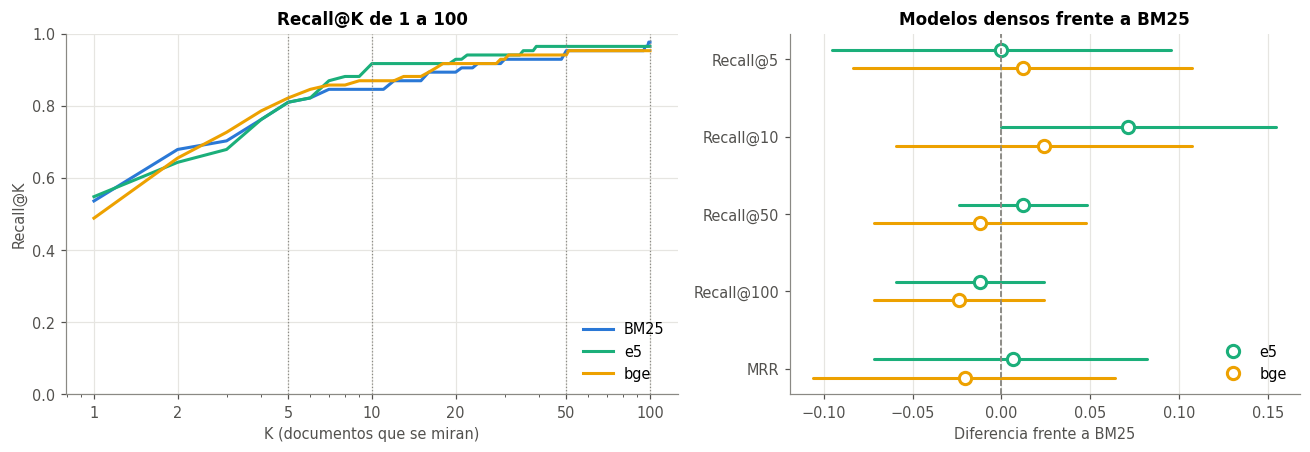

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})

# Izquierda: Recall@K de 1 a 100 para los tres métodos
ks = np.arange(1, K_MAX + 1)
for metodo, r in rankings.items():
    pos = np.array([posicion(rk, rel) or np.inf for rk, rel in zip(r, relevant)])
    ax1.plot(ks, [(pos <= k).mean() for k in ks], color=COLOR[metodo], lw=2, label=metodo)
for k in CORTES:
    ax1.axvline(k, color=GRIS, lw=0.8, ls=':')
ax1.set_xscale('log')
ax1.set_xticks([1, 2, 5, 10, 20, 50, 100], ['1', '2', '5', '10', '20', '50', '100'])
ax1.set(xlabel='K (documentos que se miran)', ylabel='Recall@K', ylim=(0, 1), title='Recall@K de 1 a 100')
ax1.legend(loc='lower right')

# Derecha: diferencia frente a BM25 con su intervalo (relleno: diferencia clara)
for clave, desp in [('e5', 0.12), ('bge', -0.12)]:
    ics = [intervalo(a[clave][m] - a['BM25'][m]) for m in metricas]
    grafica_diferencias(ax2, metricas, ics, COLOR[clave], desp, clave)
ax2.set(xlabel='Diferencia frente a BM25', title='Modelos densos frente a BM25')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

- **e5 es el mejor en Recall@10**: 0,917 frente a 0,845 de BM25, es decir, 6 queries más con el documento relevante entre los 10 primeros. La diferencia está justo en el límite de ser clara (su intervalo empieza en 0).
- **Pero no lo coloca más arriba**: en Recall@5 y MRR, e5 y BM25 quedan prácticamente igual, y en Recall@100 e5 queda incluso un poco por debajo (0,964 frente a 0,976, una query). Lo que gana e5 son documentos que BM25 dejaba entre los puestos 11 y 50.
- **bge, el modelo solo en inglés, no mejora a BM25 en nada** y queda por debajo de e5 en todas las métricas. Ser multilingüe no le cuesta nada a e5 con queries en inglés, y además permitirá buscar con afirmaciones en español. **Se elige e5.**
- **Tiempo**: 30 ms por query con e5 y 23 ms con bge, frente a 1 ms de BM25. Es mucho más lento en proporción, pero despreciable frente a lo que tardará el LLM en generar el veredicto (segundos).

Como e5 y BM25 aciertan casi lo mismo en conjunto pero tienen puntos fuertes distintos (sinónimos y paráfrasis frente a nombres raros y exactos), lo natural es comprobar si fallan en queries distintas y, si es así, combinarlos.

### 1.4. ¿Cambia algo la búsqueda aproximada?

El índice HNSW de Chroma no garantiza devolver los vecinos exactos. Para comprobar que la aproximación no afecta a la evaluación, se repite la búsqueda de forma exacta (producto escalar con todos los vectores, que están normalizados) y se comparan las métricas.

In [7]:
for clave in ['e5', 'bge']:
    guardado = colecciones[clave].get(include=['embeddings'])
    E = np.asarray(guardado['embeddings'], dtype=np.float32)
    filas = np.array([fila_de_chunk[cid] for cid in guardado['ids']])
    exactos = []
    for q in queries:
        sims = E @ vector_query(q['query'], clave)[0]
        orden = np.argsort(-sims)[:n_fragmentos(K_MAX)]
        exactos.append(a_documentos(filas[orden], K_MAX))
    iguales = np.mean([r1[:10] == r2[:10] for r1, r2 in zip(exactos, rankings[clave])])
    print(f"{clave}: top 10 idéntico en el {100 * iguales:.0f} % de las queries")
    print(pd.DataFrame({'HNSW (Chroma)': a[clave].mean(), 'exacta': aciertos(exactos, relevant).mean()})
          .round(3).T.to_string(), '\n')

e5: top 10 idéntico en el 61 % de las queries
               Recall@5  Recall@10  Recall@50  Recall@100    MRR
HNSW (Chroma)      0.81      0.917      0.964       0.964  0.651
exacta             0.81      0.917      0.964       0.964  0.657 

bge: top 10 idéntico en el 86 % de las queries
               Recall@5  Recall@10  Recall@50  Recall@100    MRR
HNSW (Chroma)     0.821      0.869       0.94       0.952  0.624
exacta            0.821      0.869       0.94       0.952  0.625 



Las métricas con la búsqueda aproximada de Chroma y con la exacta son prácticamente iguales (el MRR de e5 cambia en la tercera cifra: 0,651 frente a 0,657), así que la aproximación no afecta a la evaluación. Que el top 10 solo sea idéntico en el 61 % de las queries con e5 se debe, con toda probabilidad, a documentos con una similitud casi igual que intercambian su orden; no se ha comprobado uno a uno, pero no cambia en qué puesto queda el documento relevante más que en algún caso aislado.

### 1.5. ¿Fallan en las mismas queries?

e5 y BM25 aciertan casi lo mismo en conjunto, pero tienen puntos fuertes distintos: e5 relaciona textos con palabras distintas y significado parecido, y BM25 acierta con nombres raros y exactos. Si fallan en queries distintas, combinarlos debería acertar más que cada uno por separado.

Para cada query, si cada método pone el documento relevante entre los 10 primeros, y en qué puesto lo deja cuando solo acierta uno de los dos. Además se comprueba si los fallos de e5 tienen que ver con los fragmentos que no le caben enteros (más de 512 *tokens*).

In [8]:
qids = [q['qid'] for q in queries]
pos = {m: [posicion(r, rel) for r, rel in zip(rankings[m], relevant)] for m in ['BM25', 'e5']}
acierta = pd.DataFrame({m: [p is not None and p <= K for p in pos[m]] for m in pos}, index=qids)

etiqueta = {True: 'acierta', False: 'falla'}
print('Documento relevante en el top 10 (número de queries):')
print(pd.crosstab(acierta['BM25'].map(etiqueta), acierta['e5'].map(etiqueta),
                  rownames=['BM25'], colnames=['e5'])
      .reindex(index=['acierta', 'falla'], columns=['acierta', 'falla'], fill_value=0).to_string())

def texto_pos(p):
    return f'>{K_MAX}' if p is None else str(p)

for titulo, filtro in [('Solo acierta BM25', acierta['BM25'] & ~acierta['e5']),
                       ('Solo acierta e5', ~acierta['BM25'] & acierta['e5']),
                       ('No acierta ninguno', ~acierta['BM25'] & ~acierta['e5'])]:
    print(f'\n{titulo}:')
    for i in np.flatnonzero(filtro.values):
        q = queries[i]
        print(f"  {q['qid']} [{q['fuente']}] BM25 {texto_pos(pos['BM25'][i]):>4s}, e5 {texto_pos(pos['e5'][i]):>4s}  {q['query']}")

# ¿Influye que el fragmento de origen no le quepa entero a e5?
fila_origen = [fila_de_chunk[q['source_chunk']] for q in queries]
textos_origen = [MODELOS['e5']['prefijo_doc'] + f"{chunks['titulo'].iat[i]}. {chunks['texto'].iat[i]}"
                 for i in fila_origen]
longitudes = np.array([len(ids) for ids in modelos['e5'].tokenizer(textos_origen)['input_ids']])
cortado = pd.Series(np.where(longitudes > 512, 'se corta', 'cabe entero'), index=qids)
print('\nFragmento de origen de la query con e5:')
print(acierta.assign(origen=cortado).groupby('origen')
      .agg(queries=('e5', 'size'), acierto_e5=('e5', 'mean'), acierto_BM25=('BM25', 'mean')).round(2).to_string())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (574 > 512). Running this sequence through the model will result in indexing errors


Documento relevante en el top 10 (número de queries):
e5       acierta  falla
BM25                   
acierta       68      3
falla          9      4

Solo acierta BM25:
  q017 [clasicos] BM25    3, e5   22  statue brought to life by Venus and later poets who retold the tale
  q026 [clasicos] BM25    2, e5   35  Trojan prince's wife begs him to stay on the walls so their child is not left fatherless
  q083 [clasicos] BM25    4, e5 >100  wooden horse debate in Greek mythology

Solo acierta e5:
  q004 [wikipedia] BM25   49, e5    2  Locrian town listed in Homer's catalogue of ships, named for its thick woods and later renamed
  q019 [clasicos] BM25   96, e5    4  Apollo's journey through ancient Greece: temples, rivers, and oracular sites established along his path
  q022 [clasicos] BM25 >100, e5    4  the islands of the blessed in classical myth and their echoes in English poetry
  q028 [youtube] BM25   21, e5    7  What is the role of Freyr in Norse mythology and his relationship with 

- **Se complementan.** Los dos aciertan en 68 queries y fallan en 4, pero en 12 acierta solo uno: **9 solo e5 y 3 solo BM25**.
- **Lo que gana e5 es justo lo que fallaba en el Hito 1.** En 6 de sus 9 aciertos exclusivos la query es de los clásicos y describe la escena con otras palabras: *"the islands of the blessed"* (q022), que BM25 no ponía ni entre los 100 primeros, pasa al puesto 4; *"gods flee to Egypt…"* (q084), donde el lematizador dejaba *gods* y *giants* en plural, pasa al 1; y el viaje de Apolo (q019), del 96 al 4. También recupera casos de "otro documento del mismo tema" que BM25 dejaba en los puestos 12 a 16 (q080 Faetón, q082 la cueva del Sueño, q092 Diomedes).
- **BM25 sigue ganando en 3 queries**, las tres de los clásicos. En q083 (*"wooden horse debate…"*) e5 ni siquiera pone el documento entre los 100 primeros.
- **Fallan los dos en 4**: q016 y q078, que ya eran los fallos más lejanos del Hito 1 (vocabulario muy distinto al del texto), y q032 y q034, en los que gana otro documento del mismo tema (puestos 16 a 50).
- **Los fragmentos cortados no explican nada aquí**: solo 1 de los 84 fragmentos de origen no le cabe entero a e5, y además lo acierta. Afectan al 5,7 % del corpus, pero no a la evaluación, así que no se añade el segundo vector por ahora; queda como limitación.

### 1.6. Búsqueda híbrida

Para combinar BM25 y e5 se usa la **fusión por rangos recíprocos** (*Reciprocal Rank Fusion*, RRF): cada fragmento suma, por cada método que lo recupera, una puntuación que solo depende de su puesto,

$$\text{RRF}(f) = \sum_{m \in \{\text{BM25},\ \text{e5}\}} \frac{1}{c + \text{puesto}_m(f)}$$

y se ordena por esa suma. Tiene dos ventajas: no hace falta poner en la misma escala las puntuaciones de BM25 y la similitud coseno, que no tienen nada que ver, y premia a los fragmentos que los dos métodos colocan arriba. Se usa $c = 60$, el valor propuesto por sus autores (Cormack et al., 2009), sin ajustarlo con nuestras queries para no inflar los resultados.

La fusión se hace con los **fragmentos** (los 2.000 primeros de cada método), porque son lo que el sistema pasará al LLM; después se pasa a documentos igual que en el resto de la evaluación.

In [9]:
N_FRAG = n_fragmentos(K_MAX)
RRF_C = 60

def filas_bm25(tokens_query, n=N_FRAG):
    if not tokens_query:
        return []
    filas, _ = bm25.retrieve([tokens_query], k=n, show_progress=False)
    return list(filas[0])

def filas_denso(texto, clave='e5', n=N_FRAG):
    res = colecciones[clave].query(query_embeddings=vector_query(texto, clave).tolist(),
                                   n_results=n, include=['distances'])
    return [fila_de_chunk[cid] for cid in res['ids'][0]]

def fusion_rrf(*listas, c=RRF_C):
    # Cada fragmento suma 1 / (c + puesto) por cada lista en la que aparece
    puntos = {}
    for lista in listas:
        for puesto, fila in enumerate(lista, 1):
            puntos[fila] = puntos.get(fila, 0) + 1 / (c + puesto)
    return sorted(puntos, key=puntos.get, reverse=True)

def retrieve_hibrida(texto, tokens_query, k=K):
    return a_documentos(fusion_rrf(filas_bm25(tokens_query), filas_denso(texto)), k)

inicio = time.perf_counter()
rankings['híbrida'] = [retrieve_hibrida(q['query'], t, k=K_MAX) for q, t in zip(queries, q_tokens)]
tiempos['híbrida'] = (time.perf_counter() - inicio) / len(queries)
a['híbrida'] = aciertos(rankings['híbrida'], relevant)

tabla = pd.DataFrame({m: {x: texto_ic(*intervalo(a[m][x])) for x in metricas} for m in ['BM25', 'e5', 'híbrida']})
for base in ['BM25', 'e5']:
    tabla[f'híbrida − {base}'] = {x: texto_ic(*intervalo(a['híbrida'][x] - a[base][x])) for x in metricas}
print(f"{len(queries)} queries. Media [intervalo bootstrap del 95 %]\n")
print(tabla.to_string())
print('\nTiempo medio por query:', {m: f'{1000 * tiempos[m]:.0f} ms' for m in ['BM25', 'e5', 'híbrida']})

84 queries. Media [intervalo bootstrap del 95 %]

                            BM25                    e5               híbrida         híbrida − BM25           híbrida − e5
Recall@5    0.810 [0.726, 0.893]  0.810 [0.726, 0.893]  0.845 [0.774, 0.917]  0.036 [-0.024, 0.095]  0.036 [-0.060, 0.131]
Recall@10   0.845 [0.762, 0.917]  0.917 [0.857, 0.964]  0.917 [0.857, 0.976]   0.071 [0.012, 0.131]  0.000 [-0.060, 0.060]
Recall@50   0.952 [0.905, 0.988]  0.964 [0.917, 1.000]  0.976 [0.940, 1.000]   0.024 [0.000, 0.060]   0.012 [0.000, 0.036]
Recall@100  0.976 [0.940, 1.000]  0.964 [0.917, 1.000]  0.976 [0.940, 1.000]  0.000 [-0.036, 0.036]   0.012 [0.000, 0.036]
MRR         0.645 [0.561, 0.733]  0.651 [0.566, 0.736]  0.729 [0.650, 0.807]   0.085 [0.041, 0.132]   0.078 [0.014, 0.147]

Tiempo medio por query: {'BM25': '1 ms', 'e5': '30 ms', 'híbrida': '34 ms'}


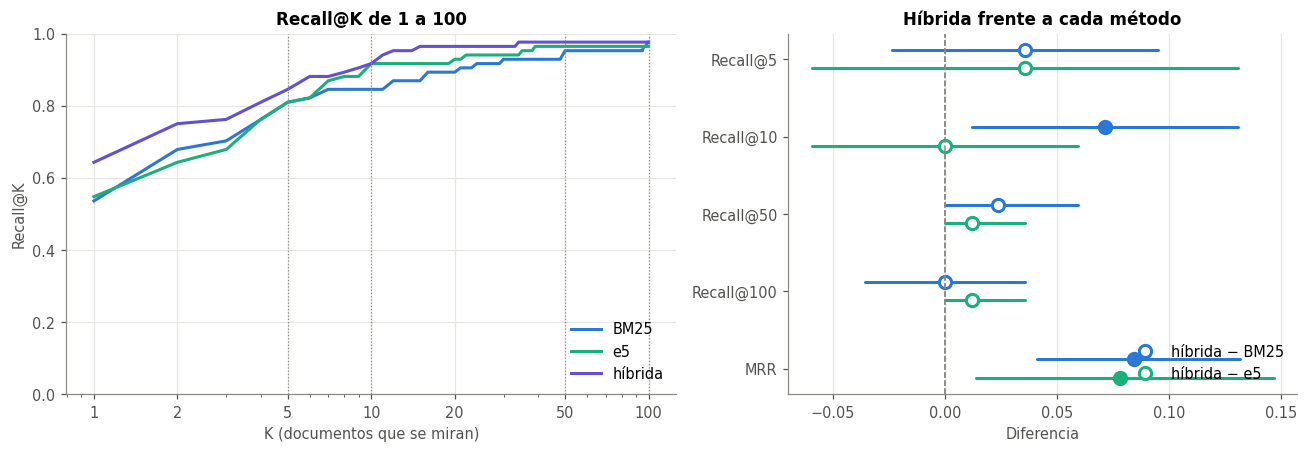

In [10]:
COLOR['híbrida'] = '#6250d6'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})

# Izquierda: Recall@K de 1 a 100
for metodo in ['BM25', 'e5', 'híbrida']:
    p = np.array([posicion(rk, rel) or np.inf for rk, rel in zip(rankings[metodo], relevant)])
    ax1.plot(ks, [(p <= k).mean() for k in ks], color=COLOR[metodo], lw=2, label=metodo)
for k in CORTES:
    ax1.axvline(k, color=GRIS, lw=0.8, ls=':')
ax1.set_xscale('log')
ax1.set_xticks([1, 2, 5, 10, 20, 50, 100], ['1', '2', '5', '10', '20', '50', '100'])
ax1.set(xlabel='K (documentos que se miran)', ylabel='Recall@K', ylim=(0, 1), title='Recall@K de 1 a 100')
ax1.legend(loc='lower right')

# Derecha: la híbrida frente a cada método por separado (relleno: diferencia clara)
for base, desp in [('BM25', 0.12), ('e5', -0.12)]:
    ics = [intervalo(a['híbrida'][m] - a[base][m]) for m in metricas]
    grafica_diferencias(ax2, metricas, ics, COLOR[base], desp, f'híbrida − {base}')
ax2.set(xlabel='Diferencia', title='Híbrida frente a cada método')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

- **La búsqueda híbrida es la mejor en todo**: Recall@10 de 0,917 (como e5 y claramente por encima de BM25, +0,071) y, sobre todo, **MRR de 0,729**, frente a 0,645 de BM25 y 0,651 de e5. Las dos diferencias de MRR son claras: +0,085 [0,041; 0,132] y +0,078 [0,014; 0,147].
- **La ganancia está en la posición**: al sumar los dos rankings, el documento que los dos métodos ven arriba sube, y los aciertos exclusivos de cada uno no se pierden. En Recall@100 queda igual que BM25 (0,976), el mejor de los dos.
- **Coste**: 35 ms por query, prácticamente lo mismo que e5 solo.
- El parámetro $c = 60$ no se ha ajustado con nuestras queries, así que esta mejora no es fruto de afinar con los mismos datos con los que se evalúa.

**Decisión: el sistema RAG recupera con la búsqueda híbrida BM25 + e5.**